# Post-hoc Conjoint Diagnostics: AI & Offshoring (`magistro2025`)

Held-out test dataset (`magistro2025`, Magistro et al. 2025): 4 respondent-clustered OLS regressions (`US AI`, `US Offshoring`, `Canada AI`, `Canada Offshoring`), each with 4 attributes × 2 non-reference AMCEs (32 AMCEs total; expected 1–5 company-decision support score).

Unlike a single-factor arm experiment, a multi-attribute conjoint evaluates four scale-invariant properties:
1. **Attribute importance shares** ($I_k$, requiring no human-dependent scaling)
2. **Within-attribute monotonicity & job loss-aversion asymmetry** ($|\hat{\beta}_{\text{cut}}| / \hat{\beta}_{\text{gain}}$)
3. **Cross-attribute trade-offs** (e.g., `Factory cut / Price $300` MRS)
4. **Shared-scale vs. shape MSE decomposition** across all 32 group × AMCE estimates

In [13]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import statsmodels.api as sm

PAPER_DIR = Path.cwd().parents[1]
REPO_DIR = PAPER_DIR.parents[2]
for p in (PAPER_DIR / "src", REPO_DIR / "code"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from beta_ols import magistro2025
import microdata_analysis as ma

MODELS = ("kev-0.8b", "kev-4b", "kev-9b")
MODEL_LABELS = {"kev-0.8b": "KEV-0.8B", "kev-4b": "KEV-4B", "kev-9b": "KEV-9B"}
BASE_SLUG = "row1_base_untrained"
TRAINED_SLUGS = ("row5_full_berke_wu_ce_oracle",)
ALL_SLUGS = (BASE_SLUG, *TRAINED_SLUGS)
REGIME_LABELS = {
    BASE_SLUG: "Off-the-shelf",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity",
}
RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")

# 1. Fit respondent-clustered human OLS for all 4 (country x shock arm) groups
choice_df = magistro2025.load_choice_df()
rows_df = magistro2025.regression_rows(choice_df)

human_fits = {}
human_betas_by_g = {}
human_se_by_g = {}
for g in magistro2025.GROUPS:
    gdf = rows_df[rows_df["group"] == g]
    fit = sm.OLS(gdf["y"], gdf[magistro2025.DESIGN_COLUMNS]).fit(
        cov_type="cluster", cov_kwds={"groups": gdf["CASEID"]}
    )
    human_fits[g] = fit
    human_betas_by_g[g] = np.array([float(fit.params[c]) for c in magistro2025.TARGET_COLUMNS])
    human_se_by_g[g] = np.array([float(fit.bse[c]) for c in magistro2025.TARGET_COLUMNS])

# Disjoint respondent groups -> exact pooled average across the 4 regressions
human_betas_avg = np.mean([human_betas_by_g[g] for g in magistro2025.GROUPS], axis=0)
human_se_avg = np.sqrt(np.sum([human_se_by_g[g] ** 2 for g in magistro2025.GROUPS], axis=0)) / len(magistro2025.GROUPS)
human_betas_32 = np.concatenate([human_betas_by_g[g] for g in magistro2025.GROUPS])

# Attribute order for plots (ordered by human importance share: Factory > Price > Customer service > Data science)
ATTR_NAMES_RAW = ("Price", "Customer service", "Factory", "Data science")
ATTR_ORDER_IDX = (2, 0, 1, 3)  # Factory, Price, Customer service, Data science
ATTR_DISPLAY_ORDER = tuple(ATTR_NAMES_RAW[k] for k in ATTR_ORDER_IDX)

# Display order of the 8 AMCE rows grouped by attribute in human-importance order
AMCE_ORDER_IDX = (
    4, 5,  # Factory: 300 (-25%), 500 (+25%)
    0, 1,  # Price: $450 (-25%), $300 (-50%)
    2, 3,  # Customer service: 75 (-25%), 125 (+25%)
    6, 7,  # Data science: 150 (-25%), 250 (+25%)
)
AMCE_SHORT_LABELS = {
    0: "Price: $450 vs. $600",
    1: "Price: $300 vs. $600",
    2: "Cust. svc: 75 vs. 100",
    3: "Cust. svc: 125 vs. 100",
    4: "Factory: 300 vs. 400",
    5: "Factory: 500 vs. 400",
    6: "Data sci: 150 vs. 200",
    7: "Data sci: 250 vs. 200",
}


def attr_importance_shares(betas_8: np.ndarray) -> np.ndarray:
    """Scale- and reference-invariant attribute importance shares I_k in ATTR_NAMES_RAW order."""
    ranges = np.empty(4, dtype=float)
    for k in range(4):
        vals = (0.0, float(betas_8[2 * k]), float(betas_8[2 * k + 1]))
        ranges[k] = max(vals) - min(vals)
    total = float(ranges.sum())
    if total <= 0.0:
        raise ValueError("Total attribute range must be positive")
    return ranges / total


def check_within_attr_monotonicity(betas_8: np.ndarray) -> list[bool]:
    """True per attribute (in ATTR_NAMES_RAW order) if levels follow human ordering relative to 0."""
    ok = [bool(betas_8[1] > betas_8[0] > 0.0)]  # Price: $300 > $450 > $600 (0)
    for k in (1, 2, 3):  # Jobs: Increase > 0 > Decrease
        ok.append(bool(betas_8[2 * k + 1] > 0.0 > betas_8[2 * k]))
    return ok


def job_loss_asymmetry(betas_by_g: dict[str, np.ndarray]) -> float:
    """Scale-invariant ratio of mean job-cut penalty to mean job-gain reward across 3 job attrs x 4 groups."""
    cuts = np.mean([-betas_by_g[g][idx] for g in magistro2025.GROUPS for idx in (2, 4, 6)])
    gains = np.mean([betas_by_g[g][idx] for g in magistro2025.GROUPS for idx in (3, 5, 7)])
    return float(cuts / gains) if gains > 0.0 else float("nan")


def factory_to_price_mrs(betas_by_g: dict[str, np.ndarray]) -> float:
    """Scale-invariant MRS: |Factory 400->300| / (Price $600->$300), averaged across the 4 groups."""
    avg = np.mean([betas_by_g[g] for g in magistro2025.GROUPS], axis=0)
    return float(-avg[4] / avg[1]) if avg[1] > 0.0 else float("nan")


human_imp_by_g = {g: attr_importance_shares(human_betas_by_g[g]) for g in magistro2025.GROUPS}
human_imp_avg = np.mean([human_imp_by_g[g] for g in magistro2025.GROUPS], axis=0)
human_asym = job_loss_asymmetry(human_betas_by_g)
human_mrs = factory_to_price_mrs(human_betas_by_g)

# 2. Load all 12 KEV test_best evaluations and verify exact agreement with human OLS
ctx = ma.load_microdata_context(
    run_roots=RUN_ROOTS,
    models=MODELS,
    base_slug=BASE_SLUG,
    trained_slugs=TRAINED_SLUGS,
    validators=("kriner2026", "grummon2025"),
)

target_labels_by_g = {
    g: [f"{magistro2025.GROUP_LABELS[g]} | {c}" for c in magistro2025.TARGET_COLUMNS]
    for g in magistro2025.GROUPS
}

kev_betas_by_g = {}
kev_betas_avg = {}
kev_betas_32 = {}
kev_imp_avg = {}
summary_rows = []

for m in MODELS:
    for s in ALL_SLUGS:
        bdf = ctx.magistro_betas_by_model[m][s]
        bm_by_g = {}
        mono_ok = 0
        imp_list = []
        imp_mae_list = []
        for g in magistro2025.GROUPS:
            lbls = target_labels_by_g[g]
            bh_saved = bdf.loc[lbls, "human_pop_beta"].to_numpy(dtype=float)
            bm_g = bdf.loc[lbls, "model_pop_beta"].to_numpy(dtype=float)
            max_diff = float(np.max(np.abs(bh_saved - human_betas_by_g[g])))
            if max_diff > 1e-9:
                raise ValueError(f"Human beta mismatch for {m}/{s}/{g}: {max_diff}")
            bm_by_g[g] = bm_g
            mono_ok += sum(check_within_attr_monotonicity(bm_g))
            imp_m = attr_importance_shares(bm_g)
            imp_list.append(imp_m)
            imp_mae_list.append(float(np.mean(np.abs(imp_m - human_imp_by_g[g])) * 100.0))

        bm_32 = np.concatenate([bm_by_g[g] for g in magistro2025.GROUPS])
        bm_avg = np.mean([bm_by_g[g] for g in magistro2025.GROUPS], axis=0)
        imp_avg = np.mean(imp_list, axis=0)

        a_star = float((bm_32 @ human_betas_32) / (bm_32 @ bm_32))
        if a_star <= 0.0:
            raise ValueError(f"Non-positive optimal scale for {m}/{s}: {a_star}")

        raw_mse_x1e3 = float(np.mean((bm_32 - human_betas_32) ** 2)) * 1e3
        shape_mse_x1e3 = float(np.mean((a_star * bm_32 - human_betas_32) ** 2)) * 1e3
        cos_sim = float((bm_32 @ human_betas_32) / (np.linalg.norm(bm_32) * np.linalg.norm(human_betas_32)))
        sign_ok = int(np.sum(np.sign(bm_32) == np.sign(human_betas_32)))

        kev_betas_by_g[(m, s)] = bm_by_g
        kev_betas_avg[(m, s)] = bm_avg
        kev_betas_32[(m, s)] = bm_32
        kev_imp_avg[(m, s)] = imp_avg

        summary_rows.append(
            {
                "model_slug": m,
                "regime_slug": s,
                "Model": MODEL_LABELS[m],
                "Regime": REGIME_LABELS[s],
                "Raw MSE (x1e3)": raw_mse_x1e3,
                "Shape MSE (x1e3)": shape_mse_x1e3,
                "Scale": 1.0 / a_star,
                "Cosine": cos_sim,
                "Signs (/32)": f"{sign_ok}/32",
                "Mono (/16)": f"{mono_ok}/16",
                "Imp. MAE (pp)": float(np.mean(imp_mae_list)),
                "Factory %": imp_avg[2] * 100.0,
                "Price %": imp_avg[0] * 100.0,
                "Cust. svc %": imp_avg[1] * 100.0,
                "Data sci %": imp_avg[3] * 100.0,
                "Job cut/gain": job_loss_asymmetry(bm_by_g),
                "Factory/Price MRS": factory_to_price_mrs(bm_by_g),
                "_a_star": a_star,
            }
        )

summary_df = pd.DataFrame(summary_rows)
row_lookup = {(r["model_slug"], r["regime_slug"]): r for r in summary_rows}
print(
    f"Loaded AI & offshoring (magistro2025): {len(rows_df):,} tasks across {rows_df['CASEID'].nunique():,} respondents, "
    f"4 groups x 8 AMCEs = 32 estimates; verified all 6 KEV runs (Off-the-shelf vs. Drones + Electricity) (max human diff < 1e-9)."
)

Loaded AI & offshoring (magistro2025): 21,005 tasks across 5,525 respondents, 4 groups x 8 AMCEs = 32 estimates; verified all 6 KEV runs (Off-the-shelf vs. Drones + Electricity) (max human diff < 1e-9).


## 1. Conjoint Summary Metrics (Human Benchmark vs. Off-the-shelf and Full Choice-Trained KEV)

Key contrast hidden by raw $\mathrm{MSE}_\beta$: `KEV-0.8B` has lower raw MSE only because its overall scale is compressed ($0.75\times$–$1.12\times$), while putting $>41\%$ of importance on `Data science jobs` and $<11\%$ on `Price`. By contrast, `KEV-9B` (`Drones + Electricity`) has the lowest shape error ($10.17$), highest cosine ($0.861$), lowest importance MAE ($8.5$ pp), and is the only model that recovers human job loss aversion (`|cut| / gain > 1.0`).

In [14]:
human_row = pd.DataFrame(
    [
        {
            "Model": "Human benchmark",
            "Regime": "—",
            "Raw MSE (x1e3)": 0.0,
            "Shape MSE (x1e3)": 0.0,
            "Scale": 1.0,
            "Cosine": 1.0,
            "Signs (/32)": "32/32",
            "Mono (/16)": "16/16",
            "Imp. MAE (pp)": 0.0,
            "Factory %": human_imp_avg[2] * 100.0,
            "Price %": human_imp_avg[0] * 100.0,
            "Cust. svc %": human_imp_avg[1] * 100.0,
            "Data sci %": human_imp_avg[3] * 100.0,
            "Job cut/gain": human_asym,
            "Factory/Price MRS": human_mrs,
        }
    ]
)

display_cols = list(human_row.columns)
tbl = pd.concat([human_row, summary_df[display_cols]], ignore_index=True)

display(
    tbl.style.format(
        {
            "Raw MSE (x1e3)": "{:.2f}",
            "Shape MSE (x1e3)": "{:.2f}",
            "Scale": "{:.2f}x",
            "Cosine": "{:.3f}",
            "Imp. MAE (pp)": "{:.1f}",
            "Factory %": "{:.1f}%",
            "Price %": "{:.1f}%",
            "Cust. svc %": "{:.1f}%",
            "Data sci %": "{:.1f}%",
            "Job cut/gain": "{:.2f}x",
            "Factory/Price MRS": "{:.2f}",
        }
    ).hide(axis="index")
)

Model,Regime,Raw MSE (x1e3),Shape MSE (x1e3),Scale,Cosine,Signs (/32),Mono (/16),Imp. MAE (pp),Factory %,Price %,Cust. svc %,Data sci %,Job cut/gain,Factory/Price MRS
Human benchmark,—,0.00,0.00,1.00x,1.000,32/32,16/16,0.0,34.6%,25.3%,20.8%,19.3%,2.74x,1.05
KEV-0.8B,Off-the-shelf,33.92,33.57,0.75x,0.382,26/32,12/16,13.3,31.3%,7.6%,15.1%,46.0%,0.47x,nan
KEV-0.8B,Drones + Electricity,26.61,26.18,0.82x,0.578,30/32,12/16,11.8,33.5%,5.2%,19.8%,41.5%,0.72x,nan
KEV-4B,Off-the-shelf,99.01,20.96,3.06x,0.683,32/32,16/16,9.8,44.5%,5.8%,24.1%,25.6%,0.75x,2.83
KEV-4B,Drones + Electricity,63.98,15.80,2.43x,0.773,32/32,16/16,9.2,47.1%,8.7%,20.3%,23.9%,0.91x,2.41
KEV-9B,Off-the-shelf,82.89,17.45,2.73x,0.746,31/32,15/16,11.8,58.3%,15.1%,13.8%,12.8%,0.82x,1.41
KEV-9B,Drones + Electricity,63.49,10.17,2.35x,0.861,30/32,14/16,8.5,51.3%,19.8%,14.0%,14.9%,1.25x,1.22


## 2. Scale-Free Conjoint Diagnostics (Zero Human-Dependent Scaling)

Both panels are computed **purely from raw model OLS coefficients**, with no scalar projection onto humans:
- **Panel A (Attribute importance shares $I_k$)**: Which attributes actually drive support decisions.
- **Panel B (Job loss-aversion asymmetry)**: Ratio of mean job-cut penalty to mean job-gain reward ($|\hat{\beta}_{\text{cut}}| / \hat{\beta}_{\text{gain}}$). Humans penalize job losses **$2.74\times$** more than they reward equal-sized job gains.

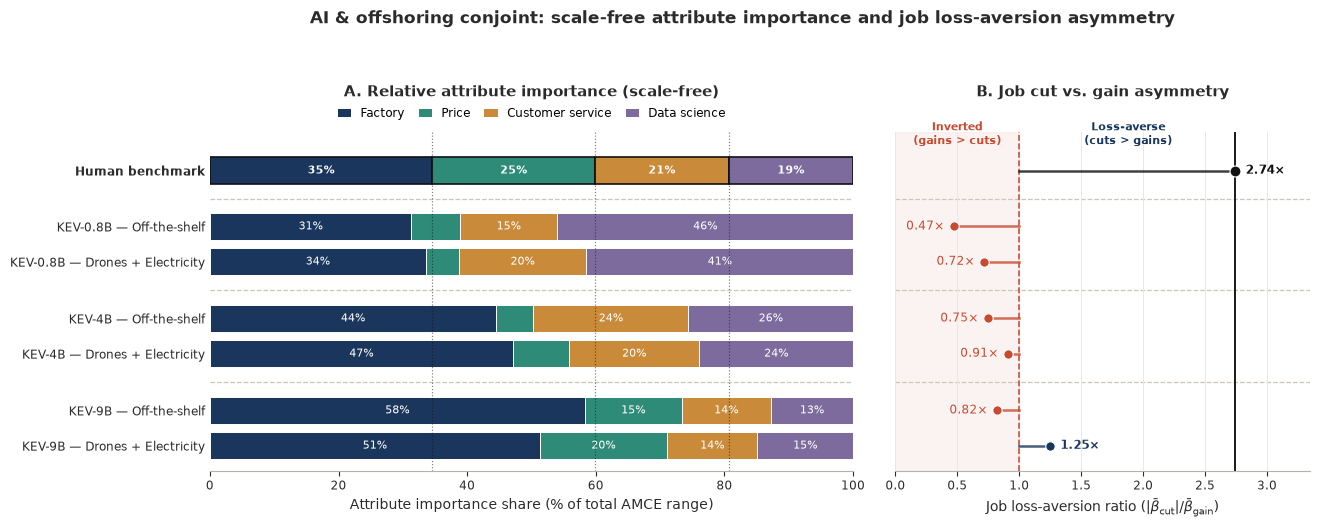

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_conjoint_diagnostics.png


In [15]:
TEXT_COLOR = "#2B2B2B"
MUTED_COLOR = "#6E6A64"
GRID_COLOR = "#EAE8E2"
HUMAN_GHOST = "#D8D5CD"
OK_COLOR = "#1B365D"
ERR_COLOR = "#C84B31"

# Colorblind-safe palette for the 4 attributes (Factory, Price, Customer service, Data science)
ATTR_COLORS = {
    "Factory": "#1B365D",          # deep navy
    "Price": "#2E8B78",            # teal
    "Customer service": "#C98A3A", # warm ochre
    "Data science": "#7D6B9E",     # muted purple
}
REGIME_DOT_COLORS = {
    BASE_SLUG: "#9A9893",
    "row2b_wu_ce_oracle": "#2E8B78",
    "row3_berke_ce_only": "#6F5091",
    "row5_full_berke_wu_ce_oracle": "#1B365D",
}

# Build y-layout with clean visual gaps between Human and each model family
row_specs = [("Human benchmark", None, None, 0.0)]
sep_ys = [0.68]
y_cursor = 1.35
for m_idx, m in enumerate(MODELS):
    for s in ALL_SLUGS:
        row_specs.append((f"{MODEL_LABELS[m]} — {REGIME_LABELS[s]}", m, s, y_cursor))
        y_cursor += 0.85
    if m_idx < len(MODELS) - 1:
        sep_ys.append(y_cursor - 0.16)
        y_cursor += 0.52

fig, (ax_imp, ax_asym) = plt.subplots(
    1,
    2,
    figsize=(14.2, 4.9),
    sharey=True,
    gridspec_kw={"width_ratios": [1.55, 1.0], "wspace": 0.08},
)

y_ticks = []
y_labels = []
for sy in sep_ys:
    ax_imp.axhline(sy, color="#CBC7BE", lw=0.9, ls="--", zorder=1)
    ax_asym.axhline(sy, color="#CBC7BE", lw=0.9, ls="--", zorder=1)

# --- Panel A: 100% Stacked Attribute Importance Shares ---
bar_h = 0.64
for label, m, s, y in row_specs:
    y_ticks.append(y)
    y_labels.append(label)
    imp = human_imp_avg if m is None else kev_imp_avg[(m, s)]
    left = 0.0
    for k_raw, attr_name in zip(ATTR_ORDER_IDX, ATTR_DISPLAY_ORDER):
        val_pct = float(imp[k_raw] * 100.0)
        edge = "#111111" if m is None else "white"
        lw = 1.2 if m is None else 0.7
        ax_imp.barh(
            y,
            val_pct,
            left=left,
            height=bar_h,
            color=ATTR_COLORS[attr_name],
            edgecolor=edge,
            linewidth=lw,
            zorder=3,
        )
        if val_pct >= 9.5:
            ax_imp.text(
                left + val_pct / 2.0,
                y,
                f"{val_pct:.0f}%",
                ha="center",
                va="center",
                fontsize=8.2,
                fontweight="bold" if m is None else "normal",
                color="white",
                zorder=4,
            )
        left += val_pct

# Subtle vertical reference guides marking the human cumulative share boundaries
cum_h = 0.0
for k_raw in ATTR_ORDER_IDX[:-1]:
    cum_h += float(human_imp_avg[k_raw] * 100.0)
    ax_imp.axvline(cum_h, color="#111111", lw=0.85, ls=":", alpha=0.55, zorder=5)

ax_imp.set_xlim(0.0, 100.0)
ax_imp.set_xlabel("Attribute importance share (% of total AMCE range)", fontsize=9.8, color=TEXT_COLOR)
ax_imp.set_title("A. Relative attribute importance (scale-free)", fontsize=11.0, fontweight="bold", color=TEXT_COLOR, pad=26)
ax_imp.set_yticks(y_ticks)
ax_imp.set_yticklabels(y_labels, fontsize=8.8, color=TEXT_COLOR)
ax_imp.get_yticklabels()[0].set_fontweight("bold")
ax_imp.spines["top"].set_visible(False)
ax_imp.spines["right"].set_visible(False)
ax_imp.spines["left"].set_visible(False)
ax_imp.spines["bottom"].set_color("#B5B2AA")
ax_imp.tick_params(axis="y", length=0)
ax_imp.tick_params(axis="x", colors=TEXT_COLOR, labelsize=8.8)

# Legend for the 4 attributes centered cleanly above Panel A
imp_handles = [mpatches.Patch(facecolor=ATTR_COLORS[a], label=a) for a in ATTR_DISPLAY_ORDER]
ax_imp.legend(
    handles=imp_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.005),
    ncol=4,
    frameon=False,
    fontsize=8.6,
    handlelength=1.1,
    columnspacing=1.2,
)

# --- Panel B: Job Loss-Aversion Asymmetry (|cut| / gain) ---
ax_asym.axvspan(0.0, 1.0, color="#F7EAE6", alpha=0.55, zorder=0)
ax_asym.axvline(1.0, color=ERR_COLOR, lw=1.15, ls="--", zorder=2)
ax_asym.axvline(human_asym, color="#111111", lw=1.35, ls="-", zorder=2)
ax_asym.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=1)

for label, m, s, y in row_specs:
    val = human_asym if m is None else row_lookup[(m, s)]["Job cut/gain"]
    color = "#111111" if m is None else (OK_COLOR if val > 1.0 else ERR_COLOR)
    ax_asym.plot([1.0, val], [y, y], color=color, lw=1.8, alpha=0.8, zorder=3)
    ax_asym.scatter(
        [val],
        [y],
        s=62 if m is None else 46,
        color=color,
        edgecolor="white",
        linewidth=0.8,
        zorder=4,
    )
    offset = 0.08 if val >= 1.0 else -0.08
    ha = "left" if val >= 1.0 else "right"
    if m is None:
        offset, ha = 0.09, "left"
    ax_asym.text(
        val + offset,
        y,
        f"{val:.2f}×",
        va="center",
        ha=ha,
        fontsize=8.3,
        fontweight="bold" if (m is None or val > 1.0) else "normal",
        color=color,
        zorder=5,
    )

# Zone callouts at top of Panel B
ax_asym.text(0.50, -0.55, "Inverted\n(gains > cuts)", ha="center", va="bottom", fontsize=7.8, color=ERR_COLOR, fontweight="bold")
ax_asym.text(1.88, -0.55, "Loss-averse\n(cuts > gains)", ha="center", va="bottom", fontsize=7.8, color=OK_COLOR, fontweight="bold")

ax_asym.set_xlim(0.0, 3.35)
ax_asym.set_ylim(y_cursor - 0.25, -0.92)
ax_asym.set_xlabel("Job loss-aversion ratio ($|\\bar{\\beta}_{\\mathrm{cut}}| / \\bar{\\beta}_{\\mathrm{gain}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_asym.set_title("B. Job cut vs. gain asymmetry", fontsize=11.0, fontweight="bold", color=TEXT_COLOR, pad=26)
ax_asym.spines["top"].set_visible(False)
ax_asym.spines["right"].set_visible(False)
ax_asym.spines["left"].set_visible(False)
ax_asym.spines["bottom"].set_color("#B5B2AA")
ax_asym.tick_params(axis="y", length=0)
ax_asym.tick_params(axis="x", colors=TEXT_COLOR, labelsize=8.8)

fig.suptitle(
    "AI & offshoring conjoint: scale-free attribute importance and job loss-aversion asymmetry",
    y=1.05,
    fontsize=12.6,
    fontweight="bold",
    color=TEXT_COLOR,
)

fig.subplots_adjust(top=0.80)
out_diag = Path("fig_ai_offshoring_conjoint_diagnostics.png")
fig.savefig(out_diag, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out_diag.resolve()}")

## 3. Attribute-Grouped AMCE Profile Grid (`3 × 2` Small Multiples)

Each panel groups the 8 pooled AMCEs into their **4 natural attribute blocks** (ordered by human importance: `Factory`, `Price`, `Customer service`, `Data science`), comparing scale-adjusted model AMCEs ($a^*\hat{\beta}_m$) against the human benchmark ($\pm 95\%$ CI, light gray bars). Coral bars flag any **sign flip** or **within-attribute monotonicity violation**.

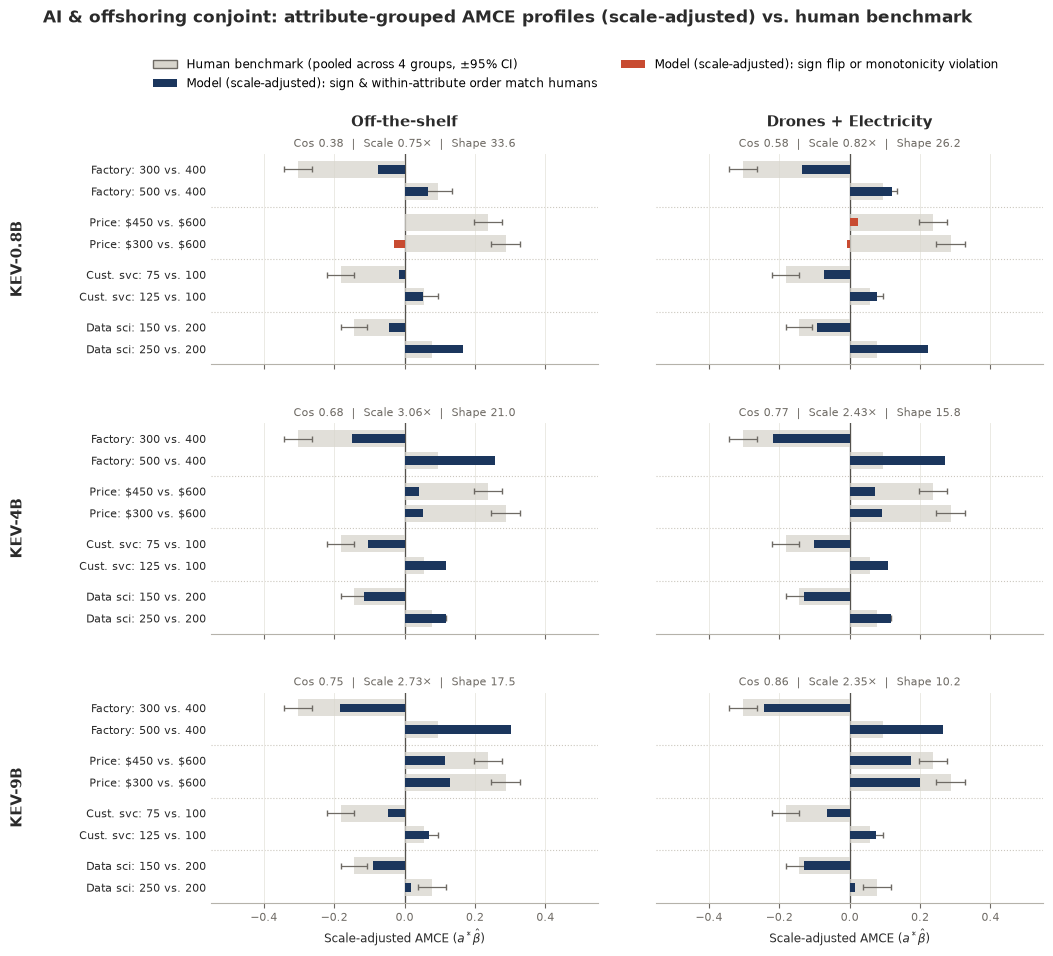

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_amce_grid.png


In [16]:
# Custom y-positions with clear gaps separating the 4 attributes (2 levels each)
y_amce = np.array([0.0, 0.85, 2.05, 2.90, 4.10, 4.95, 6.15, 7.00])
attr_sep_ys = (1.45, 3.50, 5.55)
y_amce_labels = [AMCE_SHORT_LABELS[idx].replace("$", r"\$") for idx in AMCE_ORDER_IDX]

h_ordered = human_betas_avg[list(AMCE_ORDER_IDX)]
h_se_ordered = human_se_avg[list(AMCE_ORDER_IDX)]

fig, axes = plt.subplots(
    len(MODELS),
    len(ALL_SLUGS),
    figsize=(11.4, 9.6),
    sharex=True,
    sharey=True,
    gridspec_kw={"wspace": 0.15, "hspace": 0.28},
)

for r_idx, m in enumerate(MODELS):
    for c_idx, s in enumerate(ALL_SLUGS):
        ax = axes[r_idx, c_idx]
        rec = row_lookup[(m, s)]
        a_star = rec["_a_star"]
        m_raw_avg = kev_betas_avg[(m, s)]
        m_scaled_ordered = a_star * m_raw_avg[list(AMCE_ORDER_IDX)]

        # Check within-attribute monotonicity & sign on the pooled 8-AMCE vector
        mono_by_raw_attr = check_within_attr_monotonicity(m_raw_avg)
        bar_colors = []
        for idx in AMCE_ORDER_IDX:
            attr_k = idx // 2
            sign_match = np.sign(m_raw_avg[idx]) == np.sign(human_betas_avg[idx])
            bar_colors.append(OK_COLOR if (sign_match and mono_by_raw_attr[attr_k]) else ERR_COLOR)

        ax.axvline(0.0, color="#55524D", lw=0.95, zorder=2)
        ax.grid(axis="x", color=GRID_COLOR, lw=0.65, zorder=0)
        for sy in attr_sep_ys:
            ax.axhline(sy, color="#CBC7BE", lw=0.8, ls=":", zorder=1)

        # Human benchmark ghost bars + 95% CI
        ax.barh(y_amce, h_ordered, height=0.66, color=HUMAN_GHOST, alpha=0.75, zorder=2)
        ax.errorbar(
            h_ordered,
            y_amce,
            xerr=1.96 * h_se_ordered,
            fmt="none",
            ecolor="#6E6A64",
            elinewidth=0.9,
            capsize=2.0,
            zorder=3,
        )

        # Scale-adjusted model bars
        ax.barh(y_amce, m_scaled_ordered, height=0.34, color=bar_colors, zorder=4)

        if r_idx == 0:
            ax.set_title(
                REGIME_LABELS[s],
                fontsize=10.6,
                fontweight="bold",
                color=TEXT_COLOR,
                pad=20,
            )

        ax.text(
            0.5,
            1.02,
            f"Cos {rec['Cosine']:.2f}  |  Scale {rec['Scale']:.2f}×  |  Shape {rec['Shape MSE (x1e3)']:.1f}",
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=7.6,
            color=MUTED_COLOR,
        )

        if c_idx == 0:
            ax.set_yticks(y_amce)
            ax.set_yticklabels(y_amce_labels, fontsize=8.0, color=TEXT_COLOR)
            ax.text(
                -0.50,
                0.5,
                MODEL_LABELS[m],
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=10.8,
                fontweight="bold",
                color=TEXT_COLOR,
            )

        ax.set_xlim(-0.55, 0.55)
        ax.set_ylim(7.6, -0.6)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.spines["bottom"].set_color("#B5B2AA")
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=7.8, colors=MUTED_COLOR)
        if r_idx == len(MODELS) - 1:
            ax.set_xlabel("Scale-adjusted AMCE ($a^*\\hat{\\beta}$)", fontsize=8.5, color=TEXT_COLOR)

legend_handles = [
    mpatches.Patch(facecolor=HUMAN_GHOST, edgecolor="#6E6A64", label="Human benchmark (pooled across 4 groups, ±95% CI)"),
    mpatches.Patch(facecolor=OK_COLOR, label="Model (scale-adjusted): sign & within-attribute order match humans"),
    mpatches.Patch(facecolor=ERR_COLOR, label="Model (scale-adjusted): sign flip or monotonicity violation"),
]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.56, 0.956),
    ncol=2,
    frameon=False,
    fontsize=8.6,
)
fig.suptitle(
    "AI & offshoring conjoint: attribute-grouped AMCE profiles (scale-adjusted) vs. human benchmark",
    y=0.996,
    fontsize=12.6,
    fontweight="bold",
    color=TEXT_COLOR,
)
fig.subplots_adjust(left=0.24, right=0.97, top=0.845, bottom=0.065)

out_grid = Path("fig_ai_offshoring_amce_grid.png")
fig.savefig(out_grid, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out_grid.resolve()}")

## 4. Intuitively Showing Raw vs. Scale-Adjusted AMCEs for `KEV-9B` (`Drones + Electricity`)

Just like on Food labels, most of `KEV-9B`'s raw $\mathrm{MSE}_\beta$ on AI & offshoring ($84.0\%$, dropping $63.49 \to 10.17$) comes from a single uniform stretch ($2.35\times$). Coloring the 32 AMCEs by attribute also immediately reveals the **two remaining structural shape gaps**: over-reacting to `Factory: 500 vs. 400` and under-reacting to `Data sci: 250 vs. 200`.

Attribute level,Human AMCE,Raw KEV-9B,Raw / Human,Scale-adjusted (÷2.35),Scaled diff
Factory: 300 vs. 400,-0.303,-0.575,1.90x,-0.244,+0.059
Factory: 500 vs. 400,+0.095,+0.621,6.51x,+0.264,+0.169
Price: $450 vs. $600,+0.236,+0.412,1.74x,+0.175,-0.061
Price: $300 vs. $600,+0.287,+0.470,1.63x,+0.200,-0.088
Cust. svc: 75 vs. 100,-0.182,-0.154,0.85x,-0.065,+0.116
Cust. svc: 125 vs. 100,+0.056,+0.175,3.11x,+0.074,+0.018
Data sci: 150 vs. 200,-0.144,-0.309,2.15x,-0.131,+0.013
Data sci: 250 vs. 200,+0.078,+0.033,0.42x,+0.014,-0.064


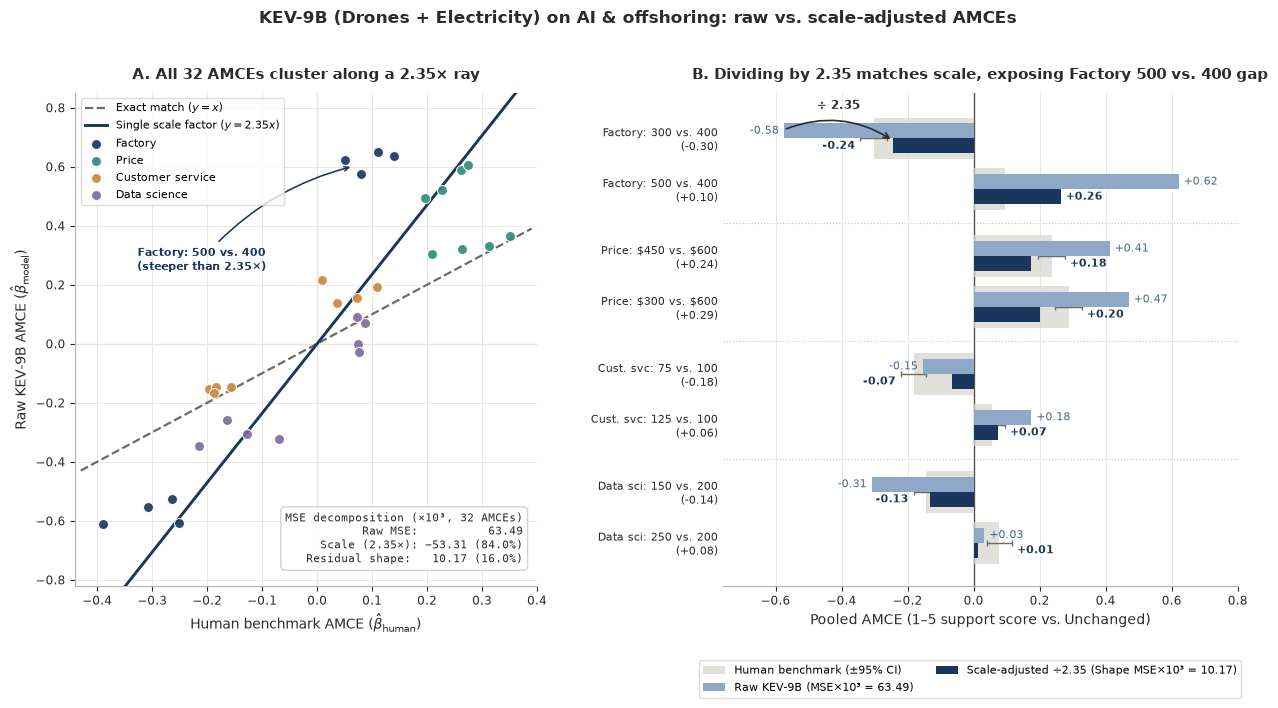

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_kev9b_raw_vs_scaled.png


In [17]:
target_m = "kev-9b"
target_s = "row5_full_berke_wu_ce_oracle"
rec9 = row_lookup[(target_m, target_s)]
a9 = rec9["_a_star"]
scale9 = rec9["Scale"]
raw_mse9 = rec9["Raw MSE (x1e3)"]
shape_mse9 = rec9["Shape MSE (x1e3)"]
scale_share9 = 100.0 * (raw_mse9 - shape_mse9) / raw_mse9

raw9_32 = kev_betas_32[(target_m, target_s)]
raw9_avg = kev_betas_avg[(target_m, target_s)]
scaled9_avg = a9 * raw9_avg

# Compact pooled 8-AMCE table for KEV-9B (Drones + Electricity)
tbl9_rows = []
for idx in AMCE_ORDER_IDX:
    hv = float(human_betas_avg[idx])
    rv = float(raw9_avg[idx])
    sv = float(scaled9_avg[idx])
    tbl9_rows.append(
        {
            "Attribute level": AMCE_SHORT_LABELS[idx],
            "Human AMCE": hv,
            "Raw KEV-9B": rv,
            "Raw / Human": rv / hv,
            f"Scale-adjusted (÷{scale9:.2f})": sv,
            "Scaled diff": sv - hv,
        }
    )
display(
    pd.DataFrame(tbl9_rows)
    .style.format(
        {
            "Human AMCE": "{:+.3f}",
            "Raw KEV-9B": "{:+.3f}",
            "Raw / Human": "{:.2f}x",
            f"Scale-adjusted (÷{scale9:.2f})": "{:+.3f}",
            "Scaled diff": "{:+.3f}",
        }
    )
    .hide(axis="index")
)

RAW_BAR_COLOR = "#8FA8C8"
SCALED_BAR_COLOR = "#1B365D"

fig, (ax_sc, ax_bar) = plt.subplots(
    1,
    2,
    figsize=(15.0, 6.4),
    gridspec_kw={"width_ratios": [1.04, 1.16], "wspace": 0.38},
)

# --- Panel A: All 32 raw AMCEs (4 groups x 8 levels) colored by attribute ---
x_grid = np.linspace(-0.43, 0.39, 100)
ax_sc.axhline(0.0, color="#CBC7BE", lw=0.85, zorder=1)
ax_sc.axvline(0.0, color="#CBC7BE", lw=0.85, zorder=1)
ax_sc.grid(color=GRID_COLOR, lw=0.7, zorder=0)

ax_sc.plot(x_grid, x_grid, color="#6E6A64", ls="--", lw=1.6, label="Exact match ($y = x$)", zorder=2)
ax_sc.plot(
    x_grid,
    scale9 * x_grid,
    color=SCALED_BAR_COLOR,
    ls="-",
    lw=2.1,
    label=f"Single scale factor ($y = {scale9:.2f}x$)",
    zorder=3,
)

# Scatter all 32 group x AMCE points grouped by attribute
for k_raw, attr_name in zip(ATTR_ORDER_IDX, ATTR_DISPLAY_ORDER):
    xs, ys = [], []
    for g in magistro2025.GROUPS:
        for lvl_offset in (0, 1):
            xs.append(float(human_betas_by_g[g][2 * k_raw + lvl_offset]))
            ys.append(float(kev_betas_by_g[(target_m, target_s)][g][2 * k_raw + lvl_offset]))
    ax_sc.scatter(
        xs,
        ys,
        s=52,
        color=ATTR_COLORS[attr_name],
        edgecolor="white",
        linewidth=0.8,
        alpha=0.92,
        label=attr_name,
        zorder=5,
    )

# Annotate the biggest shape outlier cluster (Factory: 500 jobs) in wide-open mid-left space
ax_sc.annotate(
    "Factory: 500 vs. 400\n(steeper than 2.35×)",
    xy=(float(human_betas_avg[5]) - 0.03, float(raw9_avg[5]) - 0.02),
    xytext=(-0.21, 0.25),
    ha="center",
    fontsize=8.2,
    fontweight="bold",
    color=ATTR_COLORS["Factory"],
    arrowprops=dict(arrowstyle="->", color=ATTR_COLORS["Factory"], lw=1.15, connectionstyle="arc3,rad=-0.16"),
)

# MSE decomposition box in bottom-right empty quadrant
mse_box = (
    f"MSE decomposition (×10³, 32 AMCEs)\n"
    f"Raw MSE:          {raw_mse9:>5.2f}\n"
    f"Scale ({scale9:.2f}×): −{raw_mse9 - shape_mse9:>5.2f} ({scale_share9:.1f}%)\n"
    f"Residual shape:   {shape_mse9:>5.2f} ({100.0 - scale_share9:.1f}%)"
)
ax_sc.text(
    0.97,
    0.04,
    mse_box,
    transform=ax_sc.transAxes,
    ha="right",
    va="bottom",
    fontsize=7.9,
    family="DejaVu Sans Mono",
    color=TEXT_COLOR,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#D4D2CC", alpha=0.96),
    zorder=6,
)

ax_sc.set_xlim(-0.44, 0.40)
ax_sc.set_ylim(-0.82, 0.85)
ax_sc.set_xlabel("Human benchmark AMCE ($\\hat{\\beta}_{\\mathrm{human}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_ylabel("Raw KEV-9B AMCE ($\\hat{\\beta}_{\\mathrm{model}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_title(f"A. All 32 AMCEs cluster along a {scale9:.2f}× ray", fontsize=11.0, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_sc.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=7.9, ncol=1)
ax_sc.spines["top"].set_visible(False)
ax_sc.spines["right"].set_visible(False)
ax_sc.spines["left"].set_color("#B5B2AA")
ax_sc.spines["bottom"].set_color("#B5B2AA")
ax_sc.tick_params(colors=TEXT_COLOR, labelsize=8.8)

# --- Panel B: Pooled 8 AMCEs — Raw vs Scale-adjusted vs Human ---
y_b = np.array([0.0, 0.95, 2.20, 3.15, 4.40, 5.35, 6.60, 7.55])
sep_b = (1.58, 3.78, 5.98)

ax_bar.axvline(0.0, color="#55524D", lw=1.0, zorder=2)
ax_bar.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=0)
for sy in sep_b:
    ax_bar.axhline(sy, color="#CBC7BE", lw=0.85, ls=":", zorder=1)

h_ord = human_betas_avg[list(AMCE_ORDER_IDX)]
h_se_ord = human_se_avg[list(AMCE_ORDER_IDX)]
r_ord = raw9_avg[list(AMCE_ORDER_IDX)]
s_ord = scaled9_avg[list(AMCE_ORDER_IDX)]

ax_bar.barh(y_b, h_ord, height=0.78, color=HUMAN_GHOST, alpha=0.72, label="Human benchmark (±95% CI)", zorder=2)
ax_bar.errorbar(h_ord, y_b, xerr=1.96 * h_se_ord, fmt="none", ecolor="#6E6A64", elinewidth=1.05, capsize=2.4, zorder=3)

bh = 0.28
ax_bar.barh(y_b - bh / 2, r_ord, height=bh, color=RAW_BAR_COLOR, label=f"Raw KEV-9B (MSE×10³ = {raw_mse9:.2f})", zorder=4)
ax_bar.barh(
    y_b + bh / 2,
    s_ord,
    height=bh,
    color=SCALED_BAR_COLOR,
    label=f"Scale-adjusted ÷{scale9:.2f} (Shape MSE×10³ = {shape_mse9:.2f})",
    zorder=5,
)

# Direct numeric labels for raw and scaled bars
for i in range(len(y_b)):
    rv = float(r_ord[i])
    sv = float(s_ord[i])
    hv = float(h_ord[i])
    se = float(h_se_ord[i])
    if rv >= 0.0:
        ax_bar.text(rv + 0.015, y_b[i] - bh / 2, f"{rv:+.2f}", va="center", ha="left", fontsize=7.8, color="#4A6B8A")
        ax_bar.text(max(sv, hv + 1.96 * se) + 0.015, y_b[i] + bh / 2, f"{sv:+.2f}", va="center", ha="left", fontsize=8.0, color=SCALED_BAR_COLOR, fontweight="bold")
    else:
        ax_bar.text(rv - 0.015, y_b[i] - bh / 2, f"{rv:+.2f}", va="center", ha="right", fontsize=7.8, color="#4A6B8A")
        ax_bar.text(min(sv, hv - 1.96 * se) - 0.015, y_b[i] + bh / 2, f"{sv:+.2f}", va="center", ha="right", fontsize=8.0, color=SCALED_BAR_COLOR, fontweight="bold")

# Curved contraction arrow on top bar (Factory: 300)
ax_bar.annotate(
    "",
    xy=(s_ord[0], y_b[0] + 0.04),
    xytext=(r_ord[0], y_b[0] - 0.16),
    arrowprops=dict(arrowstyle="->", color=TEXT_COLOR, lw=1.2, connectionstyle="arc3,rad=-0.26"),
    zorder=6,
)
ax_bar.text(
    0.5 * (s_ord[0] + r_ord[0]),
    y_b[0] - 0.50,
    f"÷ {scale9:.2f}",
    ha="center",
    va="bottom",
    fontsize=8.4,
    fontweight="bold",
    color=TEXT_COLOR,
)

ax_bar.set_yticks(y_b)
ax_bar.set_yticklabels(
    [f"{AMCE_SHORT_LABELS[idx].replace('$', r'\$')}\n({human_betas_avg[idx]:+.2f})" for idx in AMCE_ORDER_IDX],
    fontsize=8.0,
    color=TEXT_COLOR,
)
ax_bar.set_xlim(-0.76, 0.80)
ax_bar.set_ylim(8.35, -0.85)
ax_bar.set_xlabel("Pooled AMCE (1–5 support score vs. Unchanged)", fontsize=9.8, color=TEXT_COLOR)
ax_bar.set_title(f"B. Dividing by {scale9:.2f} matches scale, exposing Factory 500 vs. 400 gap", fontsize=11.0, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_bar.legend(loc="upper center", bbox_to_anchor=(0.48, -0.14), ncol=2, frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=8.0)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.spines["left"].set_visible(False)
ax_bar.spines["bottom"].set_color("#B5B2AA")
ax_bar.tick_params(axis="y", length=0)
ax_bar.tick_params(axis="x", colors=TEXT_COLOR, labelsize=8.8)

fig.suptitle(
    "KEV-9B (Drones + Electricity) on AI & offshoring: raw vs. scale-adjusted AMCEs",
    y=1.01,
    fontsize=12.6,
    fontweight="bold",
    color=TEXT_COLOR,
)

out_kev9 = Path("fig_ai_offshoring_kev9b_raw_vs_scaled.png")
fig.savefig(out_kev9, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out_kev9.resolve()}")

## 5. Apparent raw-MSE contradiction: Off-the-shelf `KEV-0.8B` vs. choice-trained `KEV-9B` (`Drones + Electricity`)

On raw $\mathrm{MSE}_\beta$, off-the-shelf `KEV-0.8B` (`33.92`) looks **$1.9\times$ better** than choice-trained `KEV-9B` (`63.49`). Plotting both models side by side resolves the paradox: `KEV-0.8B` stays near $y = x$ only because its overall responses are muted (`0.75×`) while scattering wildly across attributes ($99.0\%$ shape error; `cos = 0.382`), whereas `KEV-9B` hugs a straight $2.35\times$ ray ($84.0\%$ uniform scale) and achieves **$3.3\times$ lower shape MSE** (`10.17` vs. `33.57`).

Model,Raw MSE (x1e3),Scale share (%),Shape MSE (x1e3),Scale,Cosine,Imp. MAE (pp),Job cut/gain
KEV-0.8B (Off-the-shelf),33.92,1.0%,33.57,0.75x,0.382,13.3,0.47x
KEV-9B (Drones + Electricity),63.49,84.0%,10.17,2.35x,0.861,8.5,1.25x


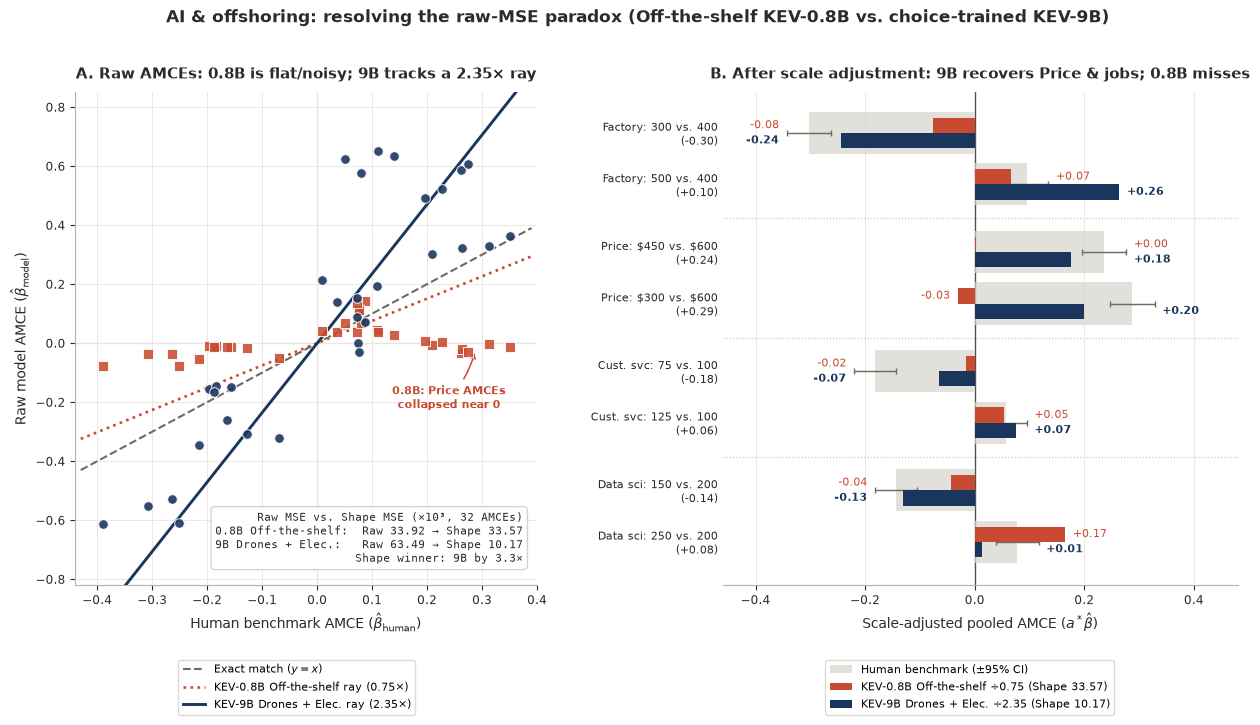

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_contradiction_08b_vs_9b.png


In [18]:
small_key = ("kev-0.8b", BASE_SLUG)
large_key = ("kev-9b", "row5_full_berke_wu_ce_oracle")

rec_s = row_lookup[small_key]
rec_l = row_lookup[large_key]

raw_s_32 = kev_betas_32[small_key]
raw_l_32 = kev_betas_32[large_key]
scaled_s_avg = rec_s["_a_star"] * kev_betas_avg[small_key]
scaled_l_avg = rec_l["_a_star"] * kev_betas_avg[large_key]

SMALL_COLOR = "#C84B31"
LARGE_COLOR = "#1B365D"

decomp2_df = pd.DataFrame(
    [
        {
            "Model": "KEV-0.8B (Off-the-shelf)",
            "Raw MSE (x1e3)": rec_s["Raw MSE (x1e3)"],
            "Scale share (%)": 100.0 * (rec_s["Raw MSE (x1e3)"] - rec_s["Shape MSE (x1e3)"]) / rec_s["Raw MSE (x1e3)"],
            "Shape MSE (x1e3)": rec_s["Shape MSE (x1e3)"],
            "Scale": rec_s["Scale"],
            "Cosine": rec_s["Cosine"],
            "Imp. MAE (pp)": rec_s["Imp. MAE (pp)"],
            "Job cut/gain": rec_s["Job cut/gain"],
        },
        {
            "Model": "KEV-9B (Drones + Electricity)",
            "Raw MSE (x1e3)": rec_l["Raw MSE (x1e3)"],
            "Scale share (%)": 100.0 * (rec_l["Raw MSE (x1e3)"] - rec_l["Shape MSE (x1e3)"]) / rec_l["Raw MSE (x1e3)"],
            "Shape MSE (x1e3)": rec_l["Shape MSE (x1e3)"],
            "Scale": rec_l["Scale"],
            "Cosine": rec_l["Cosine"],
            "Imp. MAE (pp)": rec_l["Imp. MAE (pp)"],
            "Job cut/gain": rec_l["Job cut/gain"],
        },
    ]
)
display(
    decomp2_df.style.format(
        {
            "Raw MSE (x1e3)": "{:.2f}",
            "Scale share (%)": "{:.1f}%",
            "Shape MSE (x1e3)": "{:.2f}",
            "Scale": "{:.2f}x",
            "Cosine": "{:.3f}",
            "Imp. MAE (pp)": "{:.1f}",
            "Job cut/gain": "{:.2f}x",
        }
    ).hide(axis="index")
)

fig, (ax_sc, ax_bar) = plt.subplots(
    1,
    2,
    figsize=(15.0, 6.4),
    gridspec_kw={"width_ratios": [1.04, 1.16], "wspace": 0.38},
)

# --- Panel A: Scatter of all 32 RAW AMCEs for both models against Human benchmark ---
x_grid = np.linspace(-0.43, 0.39, 100)
ax_sc.axhline(0.0, color="#CBC7BE", lw=0.85, zorder=1)
ax_sc.axvline(0.0, color="#CBC7BE", lw=0.85, zorder=1)
ax_sc.grid(color=GRID_COLOR, lw=0.7, zorder=0)

ax_sc.plot(x_grid, x_grid, color="#6E6A64", ls="--", lw=1.5, label="Exact match ($y = x$)", zorder=2)
ax_sc.plot(
    x_grid,
    rec_s["Scale"] * x_grid,
    color=SMALL_COLOR,
    ls=":",
    lw=1.9,
    label=f"KEV-0.8B Off-the-shelf ray ({rec_s['Scale']:.2f}×)",
    zorder=3,
)
ax_sc.plot(
    x_grid,
    rec_l["Scale"] * x_grid,
    color=LARGE_COLOR,
    ls="-",
    lw=2.1,
    label=f"KEV-9B Drones + Elec. ray ({rec_l['Scale']:.2f}×)",
    zorder=3,
)

ax_sc.scatter(
    human_betas_32,
    raw_s_32,
    s=42,
    marker="s",
    color=SMALL_COLOR,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.88,
    zorder=5,
)
ax_sc.scatter(
    human_betas_32,
    raw_l_32,
    s=48,
    marker="o",
    color=LARGE_COLOR,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.90,
    zorder=6,
)

# Highlight 0.8B's flat/negative Price cluster on the right
ax_sc.annotate(
    "0.8B: Price AMCEs\ncollapsed near 0",
    xy=(float(human_betas_avg[1]), float(kev_betas_avg[small_key][1])),
    xytext=(0.24, -0.22),
    ha="center",
    fontsize=8.0,
    fontweight="bold",
    color=SMALL_COLOR,
    arrowprops=dict(arrowstyle="->", color=SMALL_COLOR, lw=1.1, connectionstyle="arc3,rad=0.14"),
)

box_txt = (
    "Raw MSE vs. Shape MSE (×10³, 32 AMCEs)\n"
    f"0.8B Off-the-shelf:  Raw {rec_s['Raw MSE (x1e3)']:>5.2f} → Shape {rec_s['Shape MSE (x1e3)']:>5.2f}\n"
    f"9B Drones + Elec.:   Raw {rec_l['Raw MSE (x1e3)']:>5.2f} → Shape {rec_l['Shape MSE (x1e3)']:>5.2f}\n"
    f"Shape winner: 9B by {rec_s['Shape MSE (x1e3)'] / rec_l['Shape MSE (x1e3)']:.1f}×"
)
ax_sc.text(
    0.97,
    0.04,
    box_txt,
    transform=ax_sc.transAxes,
    ha="right",
    va="bottom",
    fontsize=7.6,
    family="DejaVu Sans Mono",
    color=TEXT_COLOR,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#D4D2CC", alpha=0.96),
    zorder=7,
)

ax_sc.set_xlim(-0.44, 0.40)
ax_sc.set_ylim(-0.82, 0.85)
ax_sc.set_xlabel("Human benchmark AMCE ($\\hat{\\beta}_{\\mathrm{human}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_ylabel("Raw model AMCE ($\\hat{\\beta}_{\\mathrm{model}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_title("A. Raw AMCEs: 0.8B is flat/noisy; 9B tracks a 2.35× ray", fontsize=10.6, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_sc.legend(loc="upper center", bbox_to_anchor=(0.48, -0.14), ncol=1, frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=8.0)
ax_sc.spines["top"].set_visible(False)
ax_sc.spines["right"].set_visible(False)
ax_sc.spines["left"].set_color("#B5B2AA")
ax_sc.spines["bottom"].set_color("#B5B2AA")
ax_sc.tick_params(colors=TEXT_COLOR, labelsize=8.8)

# --- Panel B: Scale-adjusted pooled 8 AMCEs for both models vs Human benchmark ---
y_b = np.array([0.0, 0.95, 2.20, 3.15, 4.40, 5.35, 6.60, 7.55])
sep_b = (1.58, 3.78, 5.98)

ax_bar.axvline(0.0, color="#55524D", lw=1.0, zorder=2)
ax_bar.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=0)
for sy in sep_b:
    ax_bar.axhline(sy, color="#CBC7BE", lw=0.85, ls=":", zorder=1)

h_ord = human_betas_avg[list(AMCE_ORDER_IDX)]
h_se_ord = human_se_avg[list(AMCE_ORDER_IDX)]
ss_ord = scaled_s_avg[list(AMCE_ORDER_IDX)]
sl_ord = scaled_l_avg[list(AMCE_ORDER_IDX)]

ax_bar.barh(y_b, h_ord, height=0.78, color=HUMAN_GHOST, alpha=0.72, label="Human benchmark (±95% CI)", zorder=2)
ax_bar.errorbar(h_ord, y_b, xerr=1.96 * h_se_ord, fmt="none", ecolor="#6E6A64", elinewidth=1.05, capsize=2.4, zorder=3)

bh = 0.28
ax_bar.barh(
    y_b - bh / 2,
    ss_ord,
    height=bh,
    color=SMALL_COLOR,
    label=f"KEV-0.8B Off-the-shelf ÷{rec_s['Scale']:.2f} (Shape {rec_s['Shape MSE (x1e3)']:.2f})",
    zorder=4,
)
ax_bar.barh(
    y_b + bh / 2,
    sl_ord,
    height=bh,
    color=LARGE_COLOR,
    label=f"KEV-9B Drones + Elec. ÷{rec_l['Scale']:.2f} (Shape {rec_l['Shape MSE (x1e3)']:.2f})",
    zorder=5,
)

for i in range(len(y_b)):
    vs = float(ss_ord[i])
    vl = float(sl_ord[i])
    hv = float(h_ord[i])
    se = float(h_se_ord[i])
    if vs >= 0.0:
        anchor_s = max(vs, hv + 1.96 * se) if hv > 0 else vs
        ax_bar.text(anchor_s + 0.014, y_b[i] - bh / 2, f"{vs:+.2f}", va="center", ha="left", fontsize=7.8, color=SMALL_COLOR)
    else:
        anchor_s = min(vs, hv - 1.96 * se) if hv < 0 else vs
        ax_bar.text(anchor_s - 0.014, y_b[i] - bh / 2, f"{vs:+.2f}", va="center", ha="right", fontsize=7.8, color=SMALL_COLOR)
    if vl >= 0.0:
        anchor_l = max(vl, hv + 1.96 * se) if hv > 0 else vl
        ax_bar.text(anchor_l + 0.014, y_b[i] + bh / 2, f"{vl:+.2f}", va="center", ha="left", fontsize=7.9, color=LARGE_COLOR, fontweight="bold")
    else:
        anchor_l = min(vl, hv - 1.96 * se) if hv < 0 else vl
        ax_bar.text(anchor_l - 0.014, y_b[i] + bh / 2, f"{vl:+.2f}", va="center", ha="right", fontsize=7.9, color=LARGE_COLOR, fontweight="bold")

ax_bar.set_yticks(y_b)
ax_bar.set_yticklabels(
    [f"{AMCE_SHORT_LABELS[idx].replace('$', r'\$')}\n({human_betas_avg[idx]:+.2f})" for idx in AMCE_ORDER_IDX],
    fontsize=8.0,
    color=TEXT_COLOR,
)
ax_bar.set_xlim(-0.46, 0.48)
ax_bar.set_ylim(8.35, -0.75)
ax_bar.set_xlabel("Scale-adjusted pooled AMCE ($a^*\\hat{\\beta}$)", fontsize=9.8, color=TEXT_COLOR)
ax_bar.set_title("B. After scale adjustment: 9B recovers Price & jobs; 0.8B misses", fontsize=10.6, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_bar.legend(loc="upper center", bbox_to_anchor=(0.48, -0.14), ncol=1, frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=8.0)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.spines["left"].set_visible(False)
ax_bar.spines["bottom"].set_color("#B5B2AA")
ax_bar.tick_params(axis="y", length=0)
ax_bar.tick_params(axis="x", colors=TEXT_COLOR, labelsize=8.8)

fig.suptitle(
    "AI & offshoring: resolving the raw-MSE paradox (Off-the-shelf KEV-0.8B vs. choice-trained KEV-9B)",
    y=1.01,
    fontsize=12.4,
    fontweight="bold",
    color=TEXT_COLOR,
)

out_contra2 = Path("fig_ai_offshoring_contradiction_08b_vs_9b.png")
fig.savefig(out_contra2, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out_contra2.resolve()}")

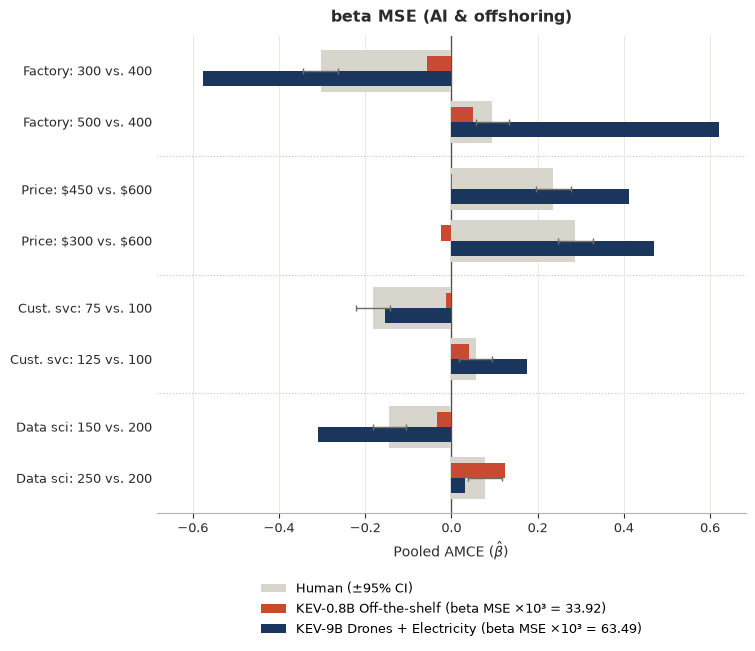

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_amce_08b_vs_9b_raw.png


In [19]:
# Two-condition AMCE plots: Off-the-shelf KEV-0.8B vs. trained KEV-9B vs. human (plot 1: raw, scored by beta MSE)
small_key = ("kev-0.8b", BASE_SLUG)
large_key = ("kev-9b", "row5_full_berke_wu_ce_oracle")
rec_small = row_lookup[small_key]
rec_large = row_lookup[large_key]

order = list(AMCE_ORDER_IDX)
human_ord = human_betas_avg[order]
human_ci_ord = 1.96 * human_se_avg[order]
small_raw_ord = kev_betas_avg[small_key][order]
large_raw_ord = kev_betas_avg[large_key][order]
small_scaled_ord = rec_small["_a_star"] * small_raw_ord
large_scaled_ord = rec_large["_a_star"] * large_raw_ord

y_pos = np.array([0.0, 0.95, 2.20, 3.15, 4.40, 5.35, 6.60, 7.55])
attr_separators = (1.58, 3.78, 5.98)
row_labels = [AMCE_SHORT_LABELS[idx].replace("$", r"\$") for idx in AMCE_ORDER_IDX]
model_bar_h = 0.28


def plot_two_condition_amces(small_vals, large_vals, small_label, large_label, x_label, title, out_path):
    fig, ax = plt.subplots(figsize=(7.6, 6.2))

    ax.axvline(0.0, color="#55524D", lw=1.0, zorder=2)
    ax.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=0)
    for sy in attr_separators:
        ax.axhline(sy, color="#CBC7BE", lw=0.85, ls=":", zorder=1)

    ax.barh(y_pos, human_ord, height=0.78, color=HUMAN_GHOST, label="Human (±95% CI)", zorder=2)
    ax.errorbar(human_ord, y_pos, xerr=human_ci_ord, fmt="none", ecolor="#6E6A64", elinewidth=1.0, capsize=2.4, zorder=6)
    ax.barh(y_pos - model_bar_h / 2, small_vals, height=model_bar_h, color="#C84B31", label=small_label, zorder=4)
    ax.barh(y_pos + model_bar_h / 2, large_vals, height=model_bar_h, color="#1B365D", label=large_label, zorder=5)

    human_extent = np.abs(human_ord) + human_ci_ord
    x_max = 1.1 * max(human_extent.max(), np.abs(small_vals).max(), np.abs(large_vals).max())

    ax.set_yticks(y_pos)
    ax.set_yticklabels(row_labels, fontsize=9.0, color=TEXT_COLOR)
    ax.set_ylim(8.2, -0.65)
    ax.set_xlim(-x_max, x_max)
    ax.set_xlabel(x_label, fontsize=10.0, color=TEXT_COLOR)
    ax.set_title(title, fontsize=11.5, fontweight="bold", color=TEXT_COLOR, pad=10)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, frameon=False, fontsize=9.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#B5B2AA")
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=TEXT_COLOR, labelsize=9.0)

    fig.savefig(out_path, dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved {out_path.resolve()}")


plot_two_condition_amces(
    small_vals=small_raw_ord,
    large_vals=large_raw_ord,
    small_label=f"KEV-0.8B Off-the-shelf (beta MSE ×10³ = {rec_small['Raw MSE (x1e3)']:.2f})",
    large_label=f"KEV-9B {REGIME_LABELS[large_key[1]]} (beta MSE ×10³ = {rec_large['Raw MSE (x1e3)']:.2f})",
    x_label="Pooled AMCE ($\\hat{\\beta}$)",
    title="beta MSE (AI & offshoring)",
    out_path=Path("fig_ai_offshoring_amce_08b_vs_9b_raw.png"),
)

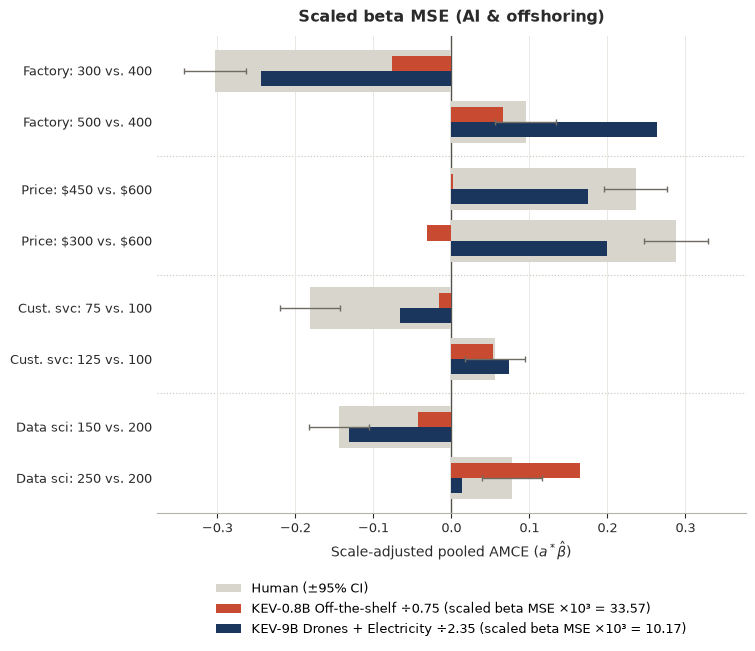

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_amce_08b_vs_9b_scaled.png


In [20]:
# Plot 2: scale-adjusted AMCEs (scored by scaled beta MSE)
plot_two_condition_amces(
    small_vals=small_scaled_ord,
    large_vals=large_scaled_ord,
    small_label=f"KEV-0.8B Off-the-shelf ÷{rec_small['Scale']:.2f} (scaled beta MSE ×10³ = {rec_small['Shape MSE (x1e3)']:.2f})",
    large_label=f"KEV-9B {REGIME_LABELS[large_key[1]]} ÷{rec_large['Scale']:.2f} (scaled beta MSE ×10³ = {rec_large['Shape MSE (x1e3)']:.2f})",
    x_label="Scale-adjusted pooled AMCE ($a^*\\hat{\\beta}$)",
    title="Scaled beta MSE (AI & offshoring)",
    out_path=Path("fig_ai_offshoring_amce_08b_vs_9b_scaled.png"),
)

## 6. Independent $\beta$ normalization (before vs. after, without human $\mathbf{h}$ rescaling)

Unlike scale adjustment via $a^*$, conjoint-style normalization rescales Human, off-the-shelf `KEV-0.8B`, and choice-trained `KEV-9B` **independently** inside each of the 4 regression groups (using zero information from the human benchmark):

1. **$L_1$-normalized ($\sum_{j=1}^8 |\tilde{\beta}_j| = 100$ per group)**: fixes total absolute AMCE mass at 100 per regression while keeping all 4 reference levels at zero.
2. **Sawtooth Zero-Centered Diffs (zero-centered within each of the 4 attributes, sum of attribute ranges $= 100$ per group)**: standard multi-attribute conjoint part-worth scaling across all 12 levels (4 attributes $\times$ 3 levels), so attribute ranges equal attribute importance percentages summing to 100.

Metric (all 4 groups),KEV-0.8B Off-the-shelf,KEV-9B Drones + Electricity,0.8B / 9B ratio,Winner
"Before: Raw beta MSE (x1e3, 32 AMCEs)",33.92,63.49,0.53x,KEV-0.8B
"After (projection): Shape MSE (x1e3, 32 AMCEs)",33.57,10.17,3.30x,KEV-9B
After (independent): L1-sum=100 MSE (32 AMCEs),298.77,53.68,5.57x,KEV-9B
After (independent): Sawtooth ZCD sum-of-ranges=100 MSE (48 levels),105.15,27.56,3.82x,KEV-9B


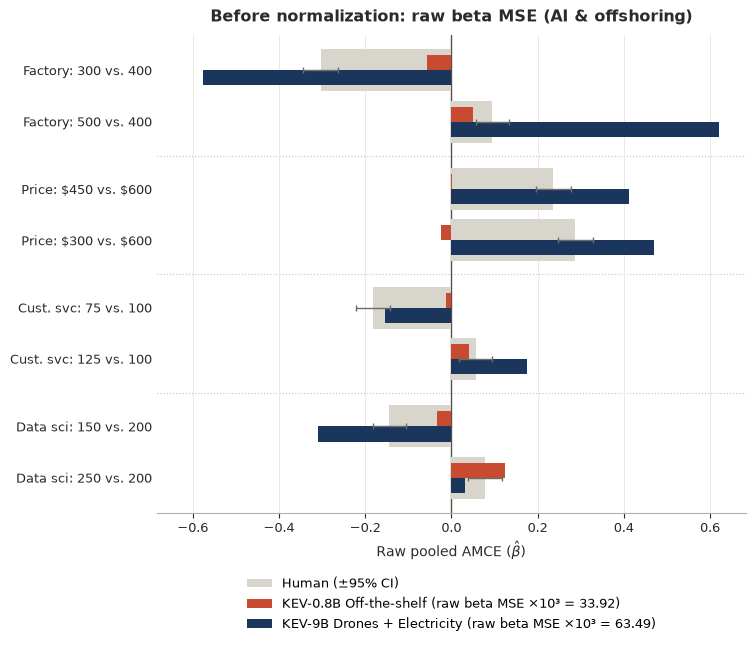

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_amce_08b_vs_9b_norm_before_raw.png


In [21]:
# Independent conjoint normalization helpers (applied per regression group, no human vector used)
M_LEVELS = np.zeros((12, 8), dtype=float)
for _k in range(4):
    M_LEVELS[3 * _k + 1, 2 * _k] = 1.0
    M_LEVELS[3 * _k + 2, 2 * _k + 1] = 1.0
C12_CENTER = np.kron(np.eye(4), np.eye(3) - np.ones((3, 3)) / 3.0)


def normalize_l1_100_group(b8: np.ndarray) -> np.ndarray:
    l1_norm = float(np.sum(np.abs(b8)))
    if l1_norm <= 0.0:
        raise ValueError(f"Non-positive L1 norm: {l1_norm}")
    return 100.0 * b8 / l1_norm


def normalize_zcd_100_group(b8: np.ndarray) -> np.ndarray:
    u = M_LEVELS @ b8
    total_range = sum(float(u[3 * k : 3 * k + 3].max() - u[3 * k : 3 * k + 3].min()) for k in range(4))
    if total_range <= 0.0:
        raise ValueError(f"Non-positive total attribute range: {total_range}")
    return 100.0 * (C12_CENTER @ u) / total_range


# Compute per-group normalized vectors and exact delta-method pooled CIs for Human (disjoint respondent groups)
human_l1_by_g = {}
human_zcd_by_g = {}
V_human_l1_sum = np.zeros((8, 8), dtype=float)
V_human_zcd_sum = np.zeros((12, 12), dtype=float)

for g in magistro2025.GROUPS:
    h8 = human_betas_by_g[g]
    if not np.all(np.abs(h8) > 0.0):
        raise ValueError(f"Zero human slope encountered in {g}; L1 Jacobian undefined")
    Vg = human_fits[g].cov_params().loc[magistro2025.TARGET_COLUMNS, magistro2025.TARGET_COLUMNS].to_numpy(dtype=float)

    # L1 delta-method covariance
    l1_g = float(np.sum(np.abs(h8)))
    J_l1_g = (100.0 / l1_g) * np.eye(8) - (100.0 / (l1_g**2)) * np.outer(h8, np.sign(h8))
    human_l1_by_g[g] = normalize_l1_100_group(h8)
    V_human_l1_sum += J_l1_g @ Vg @ J_l1_g.T

    # Sawtooth ZCD delta-method covariance
    u_g = M_LEVELS @ h8
    e_span = np.zeros(12, dtype=float)
    tot_r = 0.0
    for k in range(4):
        blk = u_g[3 * k : 3 * k + 3]
        srt = np.sort(blk)
        if srt[2] == srt[1] or srt[1] == srt[0]:
            raise ValueError(f"Tied extrema in {g} attr {k}; ZCD Jacobian undefined")
        e_span[3 * k + int(np.argmax(blk))] = 1.0
        e_span[3 * k + int(np.argmin(blk))] = -1.0
        tot_r += float(blk.max() - blk.min())
    J_zcd_g = (100.0 / tot_r) * (C12_CENTER @ M_LEVELS) - (100.0 / (tot_r**2)) * np.outer(
        C12_CENTER @ u_g, e_span @ M_LEVELS
    )
    human_zcd_by_g[g] = normalize_zcd_100_group(h8)
    V_human_zcd_sum += J_zcd_g @ Vg @ J_zcd_g.T

n_groups = len(magistro2025.GROUPS)
human_l1_avg = np.mean([human_l1_by_g[g] for g in magistro2025.GROUPS], axis=0)
human_l1_se_avg = np.sqrt(np.diag(V_human_l1_sum)) / n_groups
human_l1_32 = np.concatenate([human_l1_by_g[g] for g in magistro2025.GROUPS])

human_zcd_avg = np.mean([human_zcd_by_g[g] for g in magistro2025.GROUPS], axis=0)
human_zcd_se_avg = np.sqrt(np.diag(V_human_zcd_sum)) / n_groups
human_zcd_48 = np.concatenate([human_zcd_by_g[g] for g in magistro2025.GROUPS])

small_l1_by_g = {g: normalize_l1_100_group(kev_betas_by_g[small_key][g]) for g in magistro2025.GROUPS}
large_l1_by_g = {g: normalize_l1_100_group(kev_betas_by_g[large_key][g]) for g in magistro2025.GROUPS}
small_l1_avg = np.mean([small_l1_by_g[g] for g in magistro2025.GROUPS], axis=0)
large_l1_avg = np.mean([large_l1_by_g[g] for g in magistro2025.GROUPS], axis=0)
mse_small_l1 = float(np.mean((np.concatenate([small_l1_by_g[g] for g in magistro2025.GROUPS]) - human_l1_32) ** 2))
mse_large_l1 = float(np.mean((np.concatenate([large_l1_by_g[g] for g in magistro2025.GROUPS]) - human_l1_32) ** 2))

small_zcd_by_g = {g: normalize_zcd_100_group(kev_betas_by_g[small_key][g]) for g in magistro2025.GROUPS}
large_zcd_by_g = {g: normalize_zcd_100_group(kev_betas_by_g[large_key][g]) for g in magistro2025.GROUPS}
small_zcd_avg = np.mean([small_zcd_by_g[g] for g in magistro2025.GROUPS], axis=0)
large_zcd_avg = np.mean([large_zcd_by_g[g] for g in magistro2025.GROUPS], axis=0)
mse_small_zcd = float(np.mean((np.concatenate([small_zcd_by_g[g] for g in magistro2025.GROUPS]) - human_zcd_48) ** 2))
mse_large_zcd = float(np.mean((np.concatenate([large_zcd_by_g[g] for g in magistro2025.GROUPS]) - human_zcd_48) ** 2))

norm_summary_df = pd.DataFrame(
    [
        {
            "Metric (all 4 groups)": "Before: Raw beta MSE (x1e3, 32 AMCEs)",
            "KEV-0.8B Off-the-shelf": rec_small["Raw MSE (x1e3)"],
            "KEV-9B Drones + Electricity": rec_large["Raw MSE (x1e3)"],
            "0.8B / 9B ratio": rec_small["Raw MSE (x1e3)"] / rec_large["Raw MSE (x1e3)"],
            "Winner": "KEV-0.8B" if rec_small["Raw MSE (x1e3)"] < rec_large["Raw MSE (x1e3)"] else "KEV-9B",
        },
        {
            "Metric (all 4 groups)": "After (projection): Shape MSE (x1e3, 32 AMCEs)",
            "KEV-0.8B Off-the-shelf": rec_small["Shape MSE (x1e3)"],
            "KEV-9B Drones + Electricity": rec_large["Shape MSE (x1e3)"],
            "0.8B / 9B ratio": rec_small["Shape MSE (x1e3)"] / rec_large["Shape MSE (x1e3)"],
            "Winner": "KEV-9B",
        },
        {
            "Metric (all 4 groups)": "After (independent): L1-sum=100 MSE (32 AMCEs)",
            "KEV-0.8B Off-the-shelf": mse_small_l1,
            "KEV-9B Drones + Electricity": mse_large_l1,
            "0.8B / 9B ratio": mse_small_l1 / mse_large_l1,
            "Winner": "KEV-9B",
        },
        {
            "Metric (all 4 groups)": "After (independent): Sawtooth ZCD sum-of-ranges=100 MSE (48 levels)",
            "KEV-0.8B Off-the-shelf": mse_small_zcd,
            "KEV-9B Drones + Electricity": mse_large_zcd,
            "0.8B / 9B ratio": mse_small_zcd / mse_large_zcd,
            "Winner": "KEV-9B",
        },
    ]
)
display(
    norm_summary_df.style.format(
        {
            "KEV-0.8B Off-the-shelf": "{:.2f}",
            "KEV-9B Drones + Electricity": "{:.2f}",
            "0.8B / 9B ratio": "{:.2f}x",
        }
    ).hide(axis="index")
)


def plot_two_condition_amces_general(
    human_vals,
    human_ci,
    small_vals,
    large_vals,
    y_positions,
    separators,
    labels,
    small_label,
    large_label,
    x_label,
    title,
    out_path,
    figsize=(7.6, 6.2),
):
    fig, ax = plt.subplots(figsize=figsize)

    ax.axvline(0.0, color="#55524D", lw=1.0, zorder=2)
    ax.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=0)
    for sy in separators:
        ax.axhline(sy, color="#CBC7BE", lw=0.85, ls=":", zorder=1)

    ax.barh(y_positions, human_vals, height=0.78, color=HUMAN_GHOST, label="Human (±95% CI)", zorder=2)
    ax.errorbar(human_vals, y_positions, xerr=human_ci, fmt="none", ecolor="#6E6A64", elinewidth=1.0, capsize=2.4, zorder=6)
    ax.barh(y_positions - model_bar_h / 2, small_vals, height=model_bar_h, color="#C84B31", label=small_label, zorder=4)
    ax.barh(y_positions + model_bar_h / 2, large_vals, height=model_bar_h, color="#1B365D", label=large_label, zorder=5)

    human_extent = np.abs(human_vals) + human_ci
    x_max = 1.1 * max(float(human_extent.max()), float(np.abs(small_vals).max()), float(np.abs(large_vals).max()))

    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels, fontsize=9.0, color=TEXT_COLOR)
    ax.set_ylim(float(y_positions[-1]) + 0.65, -0.65)
    ax.set_xlim(-x_max, x_max)
    ax.set_xlabel(x_label, fontsize=10.0, color=TEXT_COLOR)
    ax.set_title(title, fontsize=11.5, fontweight="bold", color=TEXT_COLOR, pad=10)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=1, frameon=False, fontsize=9.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#B5B2AA")
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=TEXT_COLOR, labelsize=9.0)

    fig.savefig(out_path, dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved {out_path.resolve()}")


# Before: Raw pooled AMCEs (identical baseline for direct comparison)
plot_two_condition_amces_general(
    human_vals=human_ord,
    human_ci=human_ci_ord,
    small_vals=small_raw_ord,
    large_vals=large_raw_ord,
    y_positions=y_pos,
    separators=attr_separators,
    labels=row_labels,
    small_label=f"KEV-0.8B Off-the-shelf (raw beta MSE ×10³ = {rec_small['Raw MSE (x1e3)']:.2f})",
    large_label=f"KEV-9B {REGIME_LABELS[large_key[1]]} (raw beta MSE ×10³ = {rec_large['Raw MSE (x1e3)']:.2f})",
    x_label=r"Raw pooled AMCE ($\hat{\beta}$)",
    title="Before normalization: raw beta MSE (AI & offshoring)",
    out_path=Path("fig_ai_offshoring_amce_08b_vs_9b_norm_before_raw.png"),
)

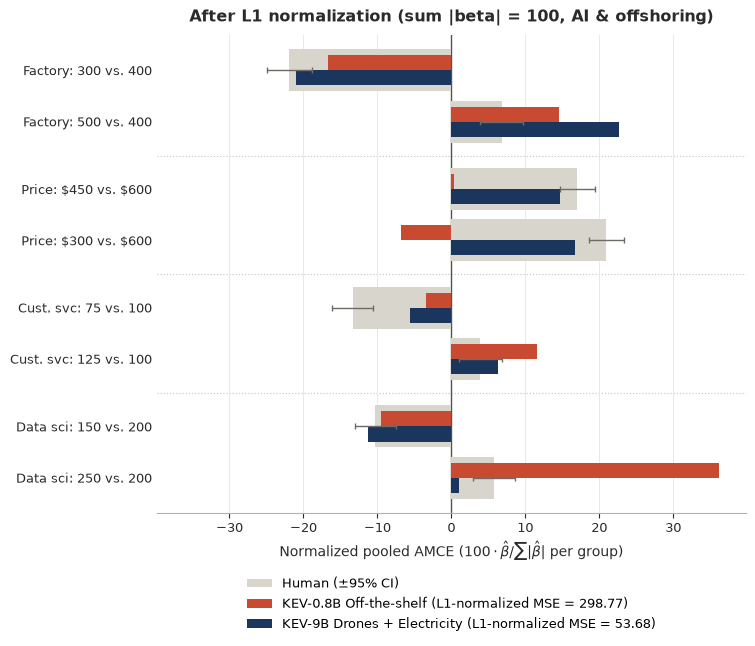

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_amce_08b_vs_9b_norm_l1_100.png


In [22]:
# After (1): Independent L1-sum = 100 normalization per group (pooled 8 AMCEs, reference = 0)
plot_two_condition_amces_general(
    human_vals=human_l1_avg[order],
    human_ci=1.96 * human_l1_se_avg[order],
    small_vals=small_l1_avg[order],
    large_vals=large_l1_avg[order],
    y_positions=y_pos,
    separators=attr_separators,
    labels=row_labels,
    small_label=f"KEV-0.8B Off-the-shelf (L1-normalized MSE = {mse_small_l1:.2f})",
    large_label=f"KEV-9B {REGIME_LABELS[large_key[1]]} (L1-normalized MSE = {mse_large_l1:.2f})",
    x_label=r"Normalized pooled AMCE ($100 \cdot \hat{\beta} / \sum |\hat{\beta}|$ per group)",
    title="After L1 normalization (sum |beta| = 100, AI & offshoring)",
    out_path=Path("fig_ai_offshoring_amce_08b_vs_9b_norm_l1_100.png"),
)

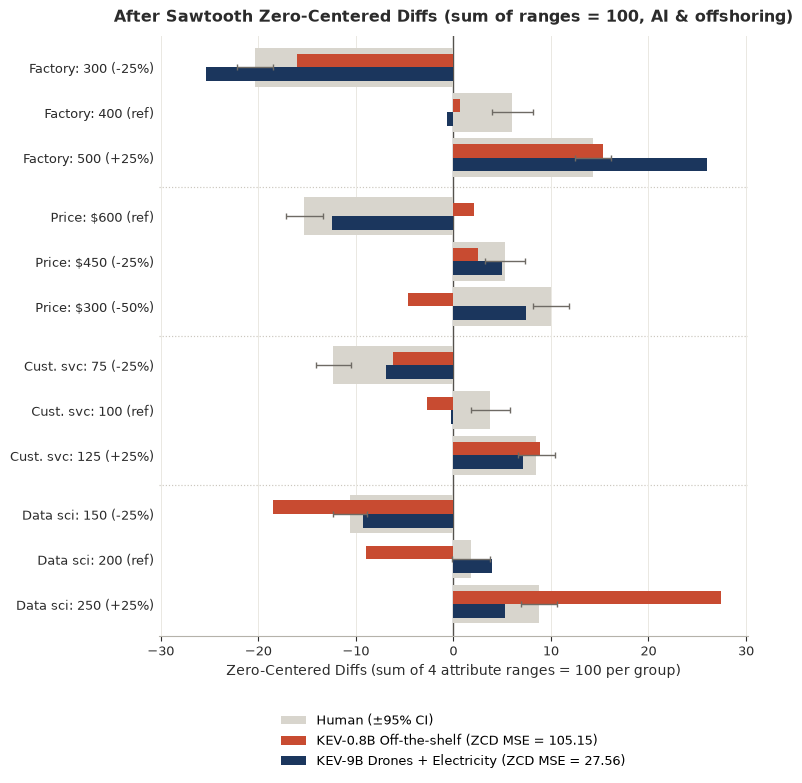

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_ai_offshoring_amce_08b_vs_9b_norm_zcd_100.png


In [23]:
# After (2): Independent Sawtooth Zero-Centered Diffs (4 attributes x 3 levels, sum of ranges = 100 per group)
ZCD_ORDER_IDX = [
    7, 6, 8,     # Factory: 300 (-25%), 400 (ref), 500 (+25%)
    0, 1, 2,     # Price: $600 (ref), $450 (-25%), $300 (-50%)
    4, 3, 5,     # Cust. svc: 75 (-25%), 100 (ref), 125 (+25%)
    10, 9, 11,   # Data sci: 150 (-25%), 200 (ref), 250 (+25%)
]
ZCD_LABELS = [
    "Factory: 300 (-25%)",
    "Factory: 400 (ref)",
    "Factory: 500 (+25%)",
    r"Price: \$600 (ref)",
    r"Price: \$450 (-25%)",
    r"Price: \$300 (-50%)",
    "Cust. svc: 75 (-25%)",
    "Cust. svc: 100 (ref)",
    "Cust. svc: 125 (+25%)",
    "Data sci: 150 (-25%)",
    "Data sci: 200 (ref)",
    "Data sci: 250 (+25%)",
]
y_pos_zcd = np.array([0.0, 0.92, 1.84, 3.04, 3.96, 4.88, 6.08, 7.00, 7.92, 9.12, 10.04, 10.96])
zcd_separators = (2.44, 5.48, 8.52)

plot_two_condition_amces_general(
    human_vals=human_zcd_avg[ZCD_ORDER_IDX],
    human_ci=1.96 * human_zcd_se_avg[ZCD_ORDER_IDX],
    small_vals=small_zcd_avg[ZCD_ORDER_IDX],
    large_vals=large_zcd_avg[ZCD_ORDER_IDX],
    y_positions=y_pos_zcd,
    separators=zcd_separators,
    labels=ZCD_LABELS,
    small_label=f"KEV-0.8B Off-the-shelf (ZCD MSE = {mse_small_zcd:.2f})",
    large_label=f"KEV-9B {REGIME_LABELS[large_key[1]]} (ZCD MSE = {mse_large_zcd:.2f})",
    x_label="Zero-Centered Diffs (sum of 4 attribute ranges = 100 per group)",
    title="After Sawtooth Zero-Centered Diffs (sum of ranges = 100, AI & offshoring)",
    out_path=Path("fig_ai_offshoring_amce_08b_vs_9b_norm_zcd_100.png"),
    figsize=(7.6, 7.8),
)